In [516]:
### Importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn as sns

# Importar base de datos Amazon

In [517]:
amazon_data = pd.read_csv("amazon_sales_data_uncleaned.csv")

## Exploracion inicial

In [518]:
amazon_data.shape

(42675, 16)

In [519]:
amazon_data.head()

,Title,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,Price_on_variant,Listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,basic variant price: 2.4GHz,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,basic variant price: nan,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIP...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314,basic variant price: nan,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXoj...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,21-08-2025 11:14
3,"Apple AirPods Pro 2 Wireless Earbuds, Active N...",4.6 out of 5 stars,"35,882",10K+ bought in past month,NaN,basic variant price: $162.24,No Discount,Best Seller,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61SUj2aKoE...,/Apple-Cancellation-Transparency-Personalized-...,21-08-2025 11:14
4,Apple AirTag 4 Pack. Keep Track of and find Yo...,4.8 out of 5 stars,"28,988",10K+ bought in past month,NaN,basic variant price: $72.74,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61bMNCeAUA...,/Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/ref...,21-08-2025 11:14


In [520]:
amazon_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Title                     42675 non-null  str  
 1   Rating                    41651 non-null  str  
 2   Number_of_reviews         41651 non-null  str  
 3   bought_in_last_month      39458 non-null  str  
 4   Current/discounted_price  30926 non-null  str  
 5   Price_on_variant          42675 non-null  str  
 6   Listed_price              42675 non-null  str  
 7   is_best_seller            42675 non-null  str  
 8   is_sponsored              42675 non-null  str  
 9   is_couponed               42675 non-null  str  
 10  buy_box_availability      28022 non-null  str  
 11  delivery_details          30955 non-null  str  
 12  sustainability_badges     3408 non-null   str  
 13  image_url                 42675 non-null  str  
 14  product_url               40606 non-null  str  
 

In [521]:
amazon_data.isna().sum()

Title                           0
Rating                       1024
Number_of_reviews            1024
bought_in_last_month         3217
Current/discounted_price    11749
Price_on_variant                0
Listed_price                    0
is_best_seller                  0
is_sponsored                    0
is_couponed                     0
buy_box_availability        14653
delivery_details            11720
sustainability_badges       39267
image_url                       0
product_url                  2069
collected_at                    0
dtype: int64

In [522]:
amazon_data.describe()

,Title,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,Price_on_variant,Listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
count,42675,41651,41651,39458,30926,42675,42675,42675,42675,42675,28022,30955,3408,42675,40606,42675
unique,8808,31,4413,59,2576,3466,911,12,2,42,1,298,16,8038,40606,331
top,"Duracell Coppertop 9V Battery, 6 Count (Pack o...",4.6 out of 5 stars,25,100+ bought in past month,29.99,basic variant price: nan,No Discount,No Badge,Organic,No Coupon,Add to cart,"Delivery Mon, Sep 1",Small Business,https://m.media-amazon.com/images/I/51Xr76m2WL...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,25-08-2025 11:07
freq,744,6151,626,8801,825,21031,30364,40814,35664,40727,28022,6189,1341,1461,1,180


In [523]:
amazon_data["buy_box_availability"].value_counts(dropna=False)

buy_box_availability
Add to cart    28022
NaN            14653
Name: count, dtype: int64

In [524]:
amazon_data["is_best_seller"].value_counts(dropna=False)

is_best_seller
No Badge             40814
Amazon's               744
Limited time deal      409
Best Seller            275
Save 30%               125
Ends in                 97
Save 10%                61
Save 18%                57
Save 17%                51
Save 12%                26
Save 9%                 14
Save 77%                 2
Name: count, dtype: int64

In [525]:
amazon_data["bought_in_last_month"].value_counts(dropna=False)

bought_in_last_month
100+ bought in past month                                                                                                                                                       8801
50+ bought in past month                                                                                                                                                        5967
200+ bought in past month                                                                                                                                                       5645
No featured offers available                                                                                                                                                    4571
NaN                                                                                                                                                                             3217
300+ bought in past month                                                 

In [526]:
amazon_data["bought_in_last_month"].value_counts().head(10)

bought_in_last_month
100+ bought in past month       8801
50+ bought in past month        5967
200+ bought in past month       5645
No featured offers available    4571
300+ bought in past month       2842
500+ bought in past month       2351
1K+ bought in past month        2084
400+ bought in past month       1436
20K+ bought in past month        772
More Buying Choices              654
Name: count, dtype: int64

In [527]:
amazon_data["Price_on_variant"].value_counts(dropna=False)

Price_on_variant
basic variant price: nan                           21031
basic variant price: 16 Count (Pack of 1)            582
basic variant price: $9.99                           324
basic variant price: $119.95                         298
basic variant price: $169.99                         264
                                                   ...  
basic variant price: 50% off coupon applied            1
basic variant price: $118.95                           1
basic variant price: $120.00 off coupon applied        1
basic variant price: $90.00 off coupon applied         1
basic variant price: $30.00 off coupon applied         1
Name: count, Length: 3466, dtype: int64

In [528]:
amazon_data["Listed_price"].value_counts(dropna=False)

Listed_price
No Discount    30364
$79.99           500
$29.99           406
$16.61           360
$23.26           283
               ...  
$226.51            1
$4,995.95          1
$16.97             1
$2,999.99          1
$950.43            1
Name: count, Length: 911, dtype: int64

## Eliminar duplicados y columnas irrelevantes

Se eliminarán los registros duplicados para evitar sesgos en el modelo (un producto repetido tendría un peso artificial mayor). Asimismo, se descartarán las columnas image_url y product_url, ya que son identificadores sin valor predictivo y la columna collected_at, que corresponde al timestamp de recolección y no aporta señal al modelo.

Por otro lado, Current/discounted_price es la variable objetivo del modelo, ya que representa el precio al que se ofrece cada producto (con o sin descuento aplicado). Dado que no es razonable imputar esta variable (el precio depende fuertemente del tipo de producto, por lo que la media o mediana introducirían un sesgo severo), se opta por eliminar las filas que no la tienen. Esta decisión es viable porque tenemos un dataset grande y leugo de elimar estas filas aun quedamos con 30926 productos

In [529]:
df = amazon_data.drop_duplicates()

df = df[df["Current/discounted_price"].notna()].copy()

df = df.drop(columns=["image_url", "product_url", "collected_at"])

df.shape


(30125, 13)

### Price_on_variant

Se eliminara esta columna ya que aproximadamenyte la mitad de los datos son nulos y algunas entradas no son precios, son descriptores del producto, por lo tanto esta columna no es confiable

In [530]:
df = df.drop(columns=["Price_on_variant"])

In [531]:
df.info()

<class 'pandas.DataFrame'>
Index: 30125 entries, 0 to 42674
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Title                     30125 non-null  str  
 1   Rating                    29536 non-null  str  
 2   Number_of_reviews         29536 non-null  str  
 3   bought_in_last_month      27098 non-null  str  
 4   Current/discounted_price  30125 non-null  str  
 5   Listed_price              30125 non-null  str  
 6   is_best_seller            30125 non-null  str  
 7   is_sponsored              30125 non-null  str  
 8   is_couponed               30125 non-null  str  
 9   buy_box_availability      27079 non-null  str  
 10  delivery_details          30012 non-null  str  
 11  sustainability_badges     2309 non-null   str  
dtypes: str(12)
memory usage: 3.0 MB


In [532]:
df.shape

(30125, 12)

In [533]:
df.head()

,Title,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,Listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN
8,Complete Protect: One plan covers all eligible...,4.0 out of 5 stars,"4,380",NaN,16.99,No Discount,No Badge,Organic,Save 50% with coupon,NaN,NaN,NaN
10,Amazon Basics 48-Pack AA Alkaline High-Perform...,4.7 out of 5 stars,"8,65,598",100K+ bought in past month,14.99,No Discount,Best Seller,Organic,No Coupon,Add to cart,"Delivery Fri, Aug 29",Safer chemicals +1 more


### Quedarnos solo con el puntaje de calificación en la columna "Rating"

Extraemos los puntages de la columna "Rating", además los valos nulos lo llenamos con el promdeio de lo demas, ya que una calificación en 0 puede sesgar nuestros datos

In [534]:
df['Rating'] = (df['Rating']).str.extract(r"([\d.]+)", flags=re.IGNORECASE).astype(float)
df['Rating'] = df['Rating'].fillna(df['Rating'].mean())


### Extraer los valores de bought_in_last_month y convertirlos a enteros

Los valores faltantes se completaron con la mediana y que estos son listados de compras y sería muy raro que una compra este en ceros

In [535]:
df['bought_in_last_month'] = (df['bought_in_last_month']
    .fillna('0')
    .astype(str)
    .str.replace('K+ bought in past month', '000', regex=False)
    .str.replace('M+ bought in past month', '000000', regex=False)
    .str.replace('+ bought in past month', '', regex=False)
    .str.extract(r'(\d+)'))
df['bought_in_last_month'] = pd.to_numeric(df['bought_in_last_month'], errors="coerce")
df['bought_in_last_month'] = df['bought_in_last_month'].fillna(df['bought_in_last_month'].mean())

In [536]:
df.head()

,Title,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,Listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6,375,300.0,89.68,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3,"2,457",6000.0,9.99,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6,"3,044",2000.0,314,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN
8,Complete Protect: One plan covers all eligible...,4.0,"4,380",0.0,16.99,No Discount,No Badge,Organic,Save 50% with coupon,NaN,NaN,NaN
10,Amazon Basics 48-Pack AA Alkaline High-Perform...,4.7,"8,65,598",100000.0,14.99,No Discount,Best Seller,Organic,No Coupon,Add to cart,"Delivery Fri, Aug 29",Safer chemicals +1 more


### Extraemos los valores de Number_of_reviews y Current/discounted_price

Quitamos las comas y las convertimos a valores númericos para poder trabajar con ellas

In [537]:
df["Current/discounted_price"] = df["Current/discounted_price"].str.replace(",", "", regex=False)
df["Current/discounted_price"] = pd.to_numeric(df["Current/discounted_price"], errors="coerce")

df["Number_of_reviews"] = df["Number_of_reviews"].str.replace(",", "", regex=False)
df["Number_of_reviews"] = pd.to_numeric(df["Number_of_reviews"], errors="coerce")

### Aplicar el descuento a los productos que lo tienen

Se creo una bandera has_discount (1 si hay descuento, 0 si no), extraemos el precio original del texto "$159.00" a número limpio, y construimos listed_price_numeric: para productos con descuento usamos el precio original extraído, y para los que no tienen descuento usamos el precio actual (que ya es el original). Así tenemos una sola columna consistente de "precio original" para todos los productos

In [538]:
df["has_discount"] = (df["Listed_price"] != "No Discount").astype(int)

listed_num = df["Listed_price"].str.extract(r"\$([\d,.]+)")[0].str.replace(",", "", regex=False)
listed_num = pd.to_numeric(listed_num, errors="coerce")
df["listed_price_numeric"] = np.where(df["has_discount"] == 1, listed_num, df["Current/discounted_price"])

### Banderas

las columnas is_best_seller, is_sponsored, is_couponed, buy_box_availability, sustainability_badges son preguntas para ver si el producto cuenta con dicha caracteristica, por lo tanto se tendran como 1 si el producto aplica esto, en caso de que no se irá a 0

In [539]:
df["has_coupon"] = (df["is_couponed"] != "No Coupon").astype(int)
df["is_sponsored_flag"] = (df["is_sponsored"] == "Sponsored").astype(int)
df["is_best_seller_flag"] = (df["is_best_seller"] == "Best Seller").astype(int)
df["buy_box_available"] = (df["buy_box_availability"] == "Add to cart").astype(int)
df["has_sustainability_badge"] = df["sustainability_badges"].notna().astype(int)


df = df.drop(columns=["Listed_price", "is_couponed", "is_sponsored", "is_best_seller", "buy_box_availability", "sustainability_badges"])

In [540]:
df["title_word_count"] = df["Title"].str.split().str.len()
df = df.drop(columns=["Title"])

### Extraer información imporatante de delivery_details

Se transformo esta feature que contenía texto libre con información de envío, en variables estructuradas y analizables: is_free_delivery (envío gratuito), delivery_cost (costo en dólares

In [541]:
df["delivery_details"].unique().tolist()

['Delivery Mon, Sep 1',
 'Delivery Fri, Aug 29',
 nan,
 'Delivery Sep 1 - 11',
 'Delivery Sep 4 - 9',
 'Delivery Sep 8 - 30',
 'Delivery Aug 28 - Sep 1',
 'Delivery Sep 1 - 2',
 'Delivery Aug 28 - Sep 3',
 'Delivery Sep 1 - 9',
 'Delivery Aug 29 - Sep 2',
 'Delivery Sep 9 - 25',
 'Delivery Aug 29 - Sep 12',
 'Delivery Sep 1 - 3',
 '$42.19 delivery',
 'Delivery Tue, Sep 2',
 'Delivery Sep 1 - 4',
 'Delivery Sep 1 - 12',
 'Delivery Aug 29 - Sep 3',
 'Delivery Sep 3 - 11',
 'Delivery Sep 3 - 15',
 '$41.20 delivery',
 '$40.35 delivery',
 'Delivery Sep 1 - 8',
 'Delivery Aug 29 - Sep 4',
 'Delivery Sep 3 - 23',
 'Ships to Pakistan',
 '$73.42 delivery',
 '$40.34 delivery',
 'Delivery Sep 8 - 26',
 '$58.05 delivery',
 'Delivery Sep 8 - 25',
 '$40.13 delivery',
 '$43.43 delivery',
 'Delivery Sep 8 - Oct 7',
 'Delivery Sep 8 - 24',
 'Delivery Sep 22 - Nov 4',
 '$40.89 delivery',
 '$44.08 delivery',
 'Delivery Aug 27 - Sep 1',
 'Delivery Sep 8 - 23',
 '$40.39 delivery',
 '$9.03 delivery Sep 8 - 

In [542]:
col = df["delivery_details"].fillna("").astype(str).str.strip()
df["is_free_delivery"] = col.str.contains("FREE", case=False).astype(int)
df["delivery_cost"] = pd.to_numeric(col.str.extract(r"\$\s*([\d]+(?:\.\d+)?)\s*delivery")[0],errors="coerce")
df["delivery_cost"] = df["delivery_cost"].fillna(0)
df = df.drop(columns=["delivery_details"])


In [543]:
df.head(10)

,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,has_discount,listed_price_numeric,has_coupon,is_sponsored_flag,is_best_seller_flag,buy_box_available,has_sustainability_badge,title_word_count,is_free_delivery,delivery_cost
0,4.6,375.0,300.0,89.68,1,159.00,1,1,0,1,1,30,0,0.0
1,4.3,2457.0,6000.0,9.99,1,15.99,0,1,0,1,0,34,0,0.0
2,4.6,3044.0,2000.0,314.00,1,349.00,0,1,0,1,0,29,0,0.0
8,4.0,4380.0,0.0,16.99,0,16.99,1,0,0,0,0,13,0,0.0
10,4.7,865598.0,100000.0,14.99,0,14.99,0,0,1,1,1,12,0,0.0
12,4.2,152.0,100.0,29.99,0,29.99,0,1,0,1,0,30,0,0.0
13,4.4,12076.0,1000.0,249.99,0,249.99,0,1,0,1,0,24,0,0.0
14,4.7,7235.0,500.0,69.95,0,69.95,0,1,0,1,1,30,0,0.0
16,4.8,198512.0,80000.0,39.97,0,39.97,0,0,1,1,1,19,0,0.0
17,4.7,625776.0,100000.0,14.49,0,14.49,0,0,1,1,1,16,0,0.0


In [544]:
df.info()

<class 'pandas.DataFrame'>
Index: 30125 entries, 0 to 42674
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rating                    30125 non-null  float64
 1   Number_of_reviews         29536 non-null  float64
 2   bought_in_last_month      30125 non-null  float64
 3   Current/discounted_price  30125 non-null  float64
 4   has_discount              30125 non-null  int64  
 5   listed_price_numeric      30125 non-null  float64
 6   has_coupon                30125 non-null  int64  
 7   is_sponsored_flag         30125 non-null  int64  
 8   is_best_seller_flag       30125 non-null  int64  
 9   buy_box_available         30125 non-null  int64  
 10  has_sustainability_badge  30125 non-null  int64  
 11  title_word_count          30125 non-null  int64  
 12  is_free_delivery          30125 non-null  int64  
 13  delivery_cost             30125 non-null  float64
dtypes: float64(6), int64(8

In [545]:
df.shape

(30125, 14)

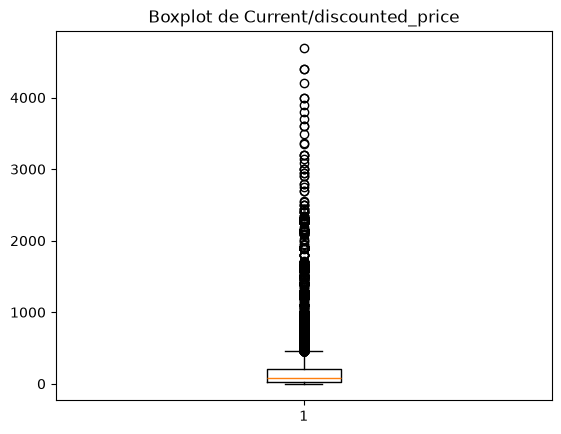

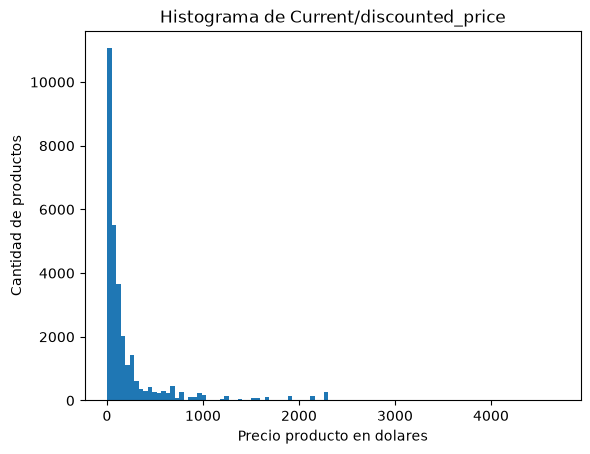

In [546]:
plt.ticklabel_format(style='plain', axis='y')


plt.boxplot(df['Current/discounted_price'])
plt.title('Boxplot de Current/discounted_price')
plt.show()

plt.hist(df['Current/discounted_price'], bins=100) 
plt.title('Histograma de Current/discounted_price')
plt.xlabel("Precio producto en dolares")
plt.ylabel("Cantidad de productos")
plt.show()

Por los graficos anteriores podemos notar que hay una gran cantidad de outliers, se pueden ver que estan a la derecha (outliers altos), vamos a verificarlo

In [547]:
import numpy as np
import pandas as pd

# Límites IQR sobre Current/discounted_price
Q1 = df['Current/discounted_price'].quantile(0.25)
Q3 = df['Current/discounted_price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
print(f"Límite inferior = {lower_bound:.2f} | Límite superior = {upper_bound:.2f}")

# Bandera de outlier (no borra nada)
df['is_outlier'] = (df['Current/discounted_price'] < lower_bound) | \
                   (df['Current/discounted_price'] > upper_bound)

print(f"Outliers bajos:  {(df['Current/discounted_price'] < lower_bound).sum()}")
print(f"Outliers altos:  {(df['Current/discounted_price'] > upper_bound).sum()}")
print(f"Total outliers:  {df['is_outlier'].sum()} ({df['is_outlier'].mean()*100:.2f}%)")

Q1 = 29.69 | Q3 = 199.99 | IQR = 170.30
Límite inferior = -225.76 | Límite superior = 455.44
Outliers bajos:  0
Outliers altos:  3720
Total outliers:  3720 (12.35%)


In [548]:
# Outliers ALTOS (los productos caros sospechosos)
outliers_altos = df[df['Current/discounted_price'] > upper_bound] \
    .sort_values('Current/discounted_price', ascending=False)

print("=== Outliers ALTOS ===")
print(outliers_altos[['Current/discounted_price', 'listed_price_numeric',
                      'Rating', 'Number_of_reviews', 'bought_in_last_month']].head(30))

# Outliers BAJOS (precios raros por debajo del límite)
outliers_bajos = df[df['Current/discounted_price'] < lower_bound] \
    .sort_values('Current/discounted_price')

print("=== Outliers BAJOS ===")
print(outliers_bajos[['Current/discounted_price', 'listed_price_numeric']].head(30))

=== Outliers ALTOS ===
       Current/discounted_price  listed_price_numeric    Rating  \
9975                    4699.00               4699.00  5.000000   
10675                   4399.00               5399.00  4.600000   
6788                    4399.00               4399.00  4.000000   
5896                    4198.00               4198.00  4.600000   
29525                   3999.99               3999.99  4.100000   
2876                    3999.00               4299.00  4.300000   
5825                    3899.99               4299.99  3.800000   
7031                    3798.00               3798.00  4.700000   
4956                    3696.95               3696.95  4.700000   
10542                   3599.00               3599.00  3.000000   
9287                    3599.00               3599.00  4.413533   
4449                    3497.97               3497.97  4.500000   
7253                    3369.95               4198.00  4.500000   
6849                    3349.99        

En efecto hay un gran cantiddad de outliers de precios muy altos.

Ahora miremos si existen productos con un precios de $0

In [549]:
# Filas donde el precio es 0 o negativo
ceros = df[df['Current/discounted_price'] <= 0]
print("Productos con precio 0 (o negativo):", len(ceros))
print(ceros[['Current/discounted_price', 'listed_price_numeric',
             'Rating', 'Number_of_reviews', 'bought_in_last_month']].head(30))

Productos con precio 0 (o negativo): 0
Empty DataFrame
Columns: [Current/discounted_price, listed_price_numeric, Rating, Number_of_reviews, bought_in_last_month]
Index: []


No existen productos con un precio de 0, esto tiene mucha lógica porque todos los productos deben tener un costo

**Limpieza de datos utilizando el IQR**

Debido a que tenemos una gran cantidad de outliers vamos a hacer una lipieza haciendo uso del rango intercuartilico el cual es la diferencia entre el tercer cuartil (Q3) y el primer cuartil (Q1).
- Matemáticamente, IQR = Q3 - Q1.

**Definición de Límites para Outliers:**

- Se establecen límites superior e inferior para identificar valores atípicos en los datos.
- El límite inferior se calcula restando 1.5 veces el IQR a Q1: lower_bound = Q1 - 1.5 * IQR.
- El límite superior se calcula sumando 1.5 veces el IQR a Q3: upper_bound = Q3 + 1.5 * IQR.

**Identificación de Outliers:**

- Cualquier valor en el conjunto de datos que sea menor que el límite inferior o mayor que el límite superior se considera un outlier.

Este enfoque, basado en el rango intercuartílico y los límites establecidos, es una técnica común para identificar y manejar valores atípicos en un conjunto de datos. La idea es que los valores atípicos están más allá de ciertos límites estadísticos y pueden ser tratados de manera especial según los requisitos del análisis.


In [550]:
print("Total de filas:", len(df))
print("Precio == 0:", (df['Current/discounted_price'] == 0).sum())
print("Precio < 0:", (df['Current/discounted_price'] < 0).sum())
print("Outliers por IQR:", df['is_outlier'].sum())
print("Quedarían tras filtrar IQR:", (~df['is_outlier']).sum())

Total de filas: 30125
Precio == 0: 0
Precio < 0: 0
Outliers por IQR: 3720
Quedarían tras filtrar IQR: 26405


In [551]:
# Calcular el rango intercuartílico (IQR)
Q1 = df['Current/discounted_price'].quantile(0.25)
Q3 = df['Current/discounted_price'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites para considerar outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_filtered = df[(df['Current/discounted_price'] >= lower_bound) & (df['Current/discounted_price'] <= upper_bound)]

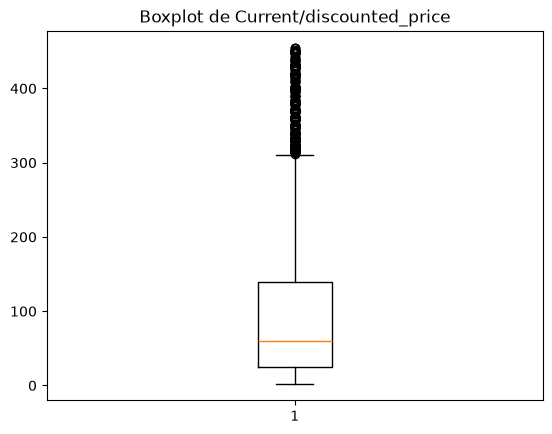

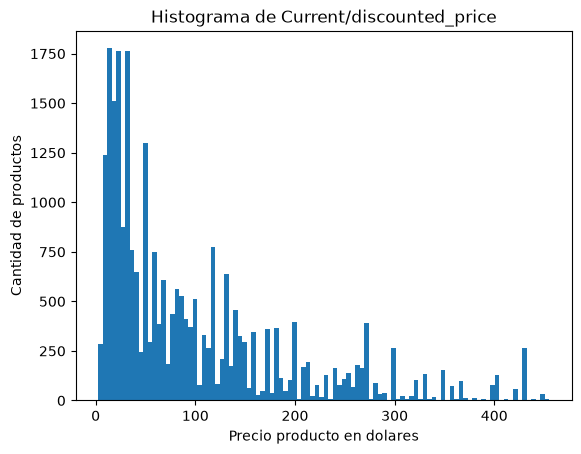

In [552]:
plt.ticklabel_format(style='plain', axis='y')


plt.boxplot(df_filtered['Current/discounted_price'])
plt.title('Boxplot de Current/discounted_price')
plt.show()

plt.hist(df_filtered['Current/discounted_price'], bins=100)
plt.title('Histograma de Current/discounted_price')
plt.xlabel("Precio producto en dolares")
plt.ylabel("Cantidad de productos")
plt.show()

In [553]:
df_filtered.shape

(26405, 15)

In [554]:
df_filtered.head()

,Rating,Number_of_reviews,bought_in_last_month,Current/discounted_price,has_discount,listed_price_numeric,has_coupon,is_sponsored_flag,is_best_seller_flag,buy_box_available,has_sustainability_badge,title_word_count,is_free_delivery,delivery_cost,is_outlier
0,4.6,375.0,300.0,89.68,1,159.00,1,1,0,1,1,30,0,0.0,False
1,4.3,2457.0,6000.0,9.99,1,15.99,0,1,0,1,0,34,0,0.0,False
2,4.6,3044.0,2000.0,314.00,1,349.00,0,1,0,1,0,29,0,0.0,False
8,4.0,4380.0,0.0,16.99,0,16.99,1,0,0,0,0,13,0,0.0,False
10,4.7,865598.0,100000.0,14.99,0,14.99,0,0,1,1,1,12,0,0.0,False


Vamos a aplicar el mismo analisis de la columna curren/discount_price a la columna bought_in_last_month

In [555]:
# Estadísticas descriptivas
print(df['bought_in_last_month'].describe())

count     30125.000000
mean        952.026914
std        4848.585677
min           0.000000
25%         100.000000
50%         200.000000
75%         500.000000
max      100000.000000
Name: bought_in_last_month, dtype: float64


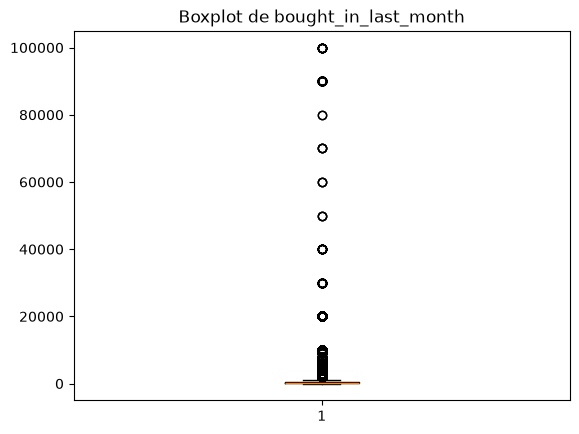

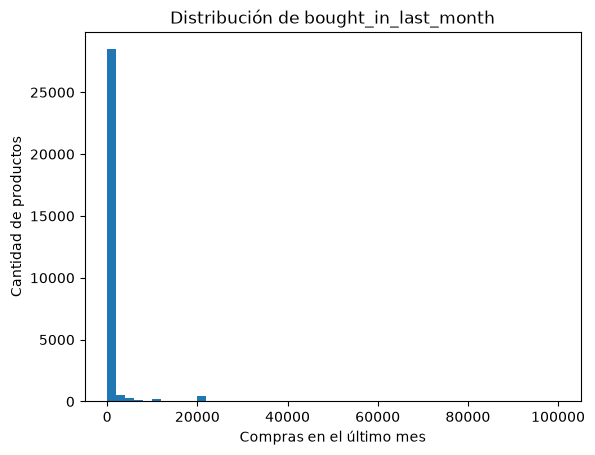

In [556]:
plt.ticklabel_format(style='plain', axis='y')

plt.boxplot(df_filtered['bought_in_last_month'])
plt.title('Boxplot de bought_in_last_month')
plt.show()

plt.hist(df['bought_in_last_month'], bins=50)
plt.title('Distribución de bought_in_last_month')
plt.xlabel('Compras en el último mes')
plt.ylabel('Cantidad de productos')
plt.show()

In [557]:
print(df['bought_in_last_month'].value_counts().head(20))

# Cuántos son 0 y cuántos valores unicos existen
print("Ceros:", (df['bought_in_last_month'] == 0).sum())
print("Valores únicos:", df['bought_in_last_month'].nunique())

bought_in_last_month
100.000000      6630
200.000000      4563
50.000000       3823
0.000000        3027
952.026914      2593
300.000000      2400
500.000000      2116
1000.000000     1560
400.000000      1314
20000.000000     412
2000.000000      357
3000.000000      205
600.000000       173
4000.000000      166
10000.000000     165
5000.000000       99
700.000000        88
6000.000000       63
800.000000        54
900.000000        49
Name: count, dtype: int64
Ceros: 3027
Valores únicos: 46


Aqui tenemos un problema, es normal que un producto tenga miles de compras, pero que un producto no tenga ninguna compra es muy poco usual.

En este caso tenemos 3027 productos que durante un mes no tuvieron ni unsa sola compra o son datos faltantes que se completaron con 0 en el parseo que se hizo anteriormente, debemos mirar que podemos hacer con esos valores tan atipicos

Revisando los nulos originales (3217) podemos deducir que los valores que son 0 son datos faltantes, en un inico eran 3217 pero ahora tenemos 3027, esto se debe a la imputaciín que hicimos en la columna Current/discounted_price.

In [558]:
Q1 = df['bought_in_last_month'].quantile(0.25)
Q3 = df['bought_in_last_month'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f"Q1={Q1:.0f} | Q3={Q3:.0f} | IQR={IQR:.0f}")
print(f"Límites: [{lower:.0f}, {upper:.0f}]")

df['bought_outlier'] = (df['bought_in_last_month'] < lower) | \
                       (df['bought_in_last_month'] > upper)

print("Outliers:", df['bought_outlier'].sum(),
      f"({df['bought_outlier'].mean()*100:.2f}%)")

Q1=100 | Q3=500 | IQR=400
Límites: [-500, 1100]
Outliers: 1666 (5.53%)


Aplicando un IQR vemos que nos dejam como datos atipicos aquellos con ventas mayores a 1100 pero no aquellos con ventas iguales a 0, para este analisis el IQR, no nos otorga una buena métrica

Por lo tanto vamos a imputar estas filas, esto ya que son muchimos datos faltantes y completarlos con la media puede introducir sesgo, ademas podemos hacerlo ya que tenemos un conjunto de datos bastante grande

In [559]:
df = df[df['bought_in_last_month'] != 0].copy()
df = df.reset_index(drop=True)

df.shape
df['bought_in_last_month'].isna().sum()
(df['bought_in_last_month'] == 0).sum()

np.int64(0)

In [560]:
print(df['bought_in_last_month'].value_counts().head(20))

# Cuántos son 0 y cuántos valores unicos existen
print("Ceros:", (df['bought_in_last_month'] == 0).sum())
print("Valores únicos:", df['bought_in_last_month'].nunique())

bought_in_last_month
100.000000      6630
200.000000      4563
50.000000       3823
952.026914      2593
300.000000      2400
500.000000      2116
1000.000000     1560
400.000000      1314
20000.000000     412
2000.000000      357
3000.000000      205
600.000000       173
4000.000000      166
10000.000000     165
5000.000000       99
700.000000        88
6000.000000       63
800.000000        54
900.000000        49
90000.000000      42
Name: count, dtype: int64
Ceros: 0
Valores únicos: 45


Ahora ya no tenemos ceros los cuales eran datos faltantes, ahora vamos a realizxar un analisis de la cantida de outliers 

In [561]:
Q1 = df['bought_in_last_month'].quantile(0.25)
Q3 = df['bought_in_last_month'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f"Q1={Q1:.0f} | Q3={Q3:.0f} | IQR={IQR:.0f}")
print(f"Límites: [{lower:.0f}, {upper:.0f}]")

# Marcar (no borrar)
df['bought_outlier'] = (df['bought_in_last_month'] < lower) | \
                       (df['bought_in_last_month'] > upper)

print("Outliers:", df['bought_outlier'].sum(),
      f"({df['bought_outlier'].mean()*100:.2f}%)")


Q1=100 | Q3=500 | IQR=400
Límites: [-500, 1100]
Outliers: 1666 (6.15%)


In [562]:
print(df.shape)

(27098, 16)


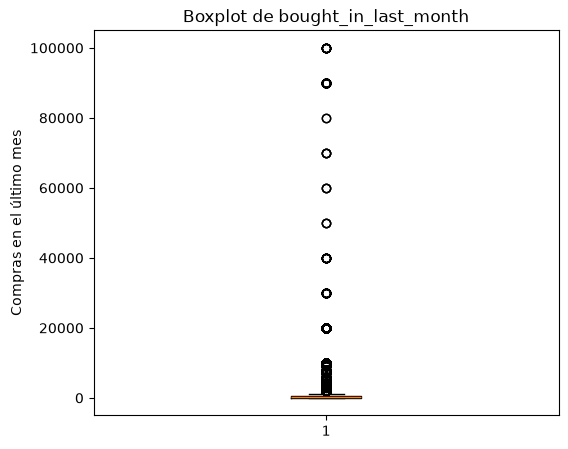

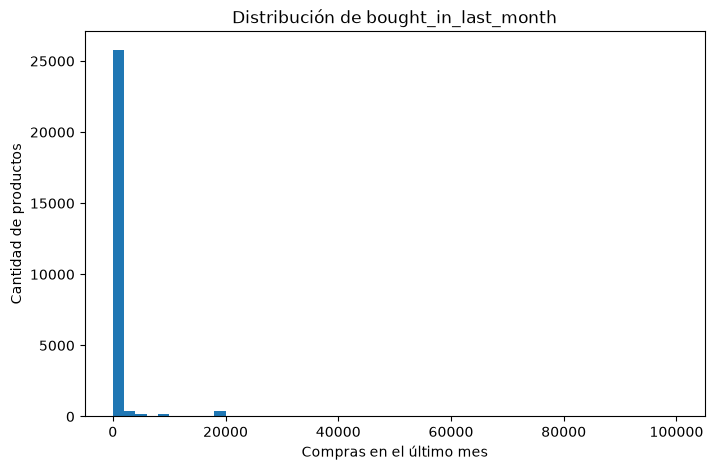

In [563]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['bought_in_last_month'])
plt.title('Boxplot de bought_in_last_month')
plt.ylabel('Compras en el último mes')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df['bought_in_last_month'], bins=50)
plt.title('Distribución de bought_in_last_month')
plt.xlabel('Compras en el último mes')
plt.ylabel('Cantidad de productos')
plt.show()

Tenemos 1666 outliers que representan un 6.15% de los datos, se tomará la desición de imputarlo ya que tenemos una gran cantidad de datos y estos outliers podrian introducri un sesgo muy grande a nuestos datos. Aunque es normal que se tengan compras muy grande de productos, esto podría introducir un sesgo a nuestro modelo.

Además notamos que al eliminar los ceros (0) las gráficas continuan mostrando una desviación de los datos y pareciera que todos son cero (0) o cercanos a cero (0), pero sabemos que ya no existen filas donde tengamos compras por valor de cero(0)

In [564]:
df = df[df['bought_in_last_month'] <= upper].copy()
df = df.reset_index(drop=True)

print("Filas con las que quedamos:", len(df))

Filas con las que quedamos: 25432


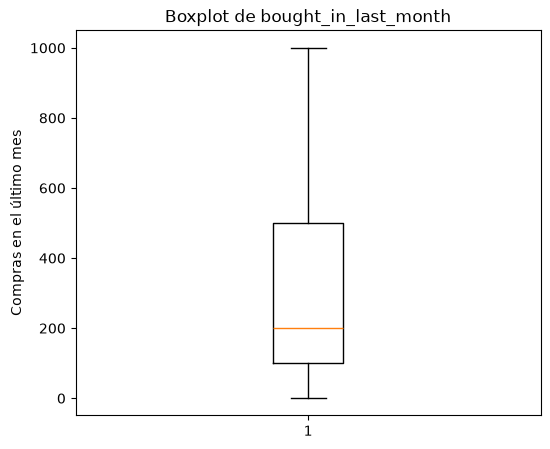

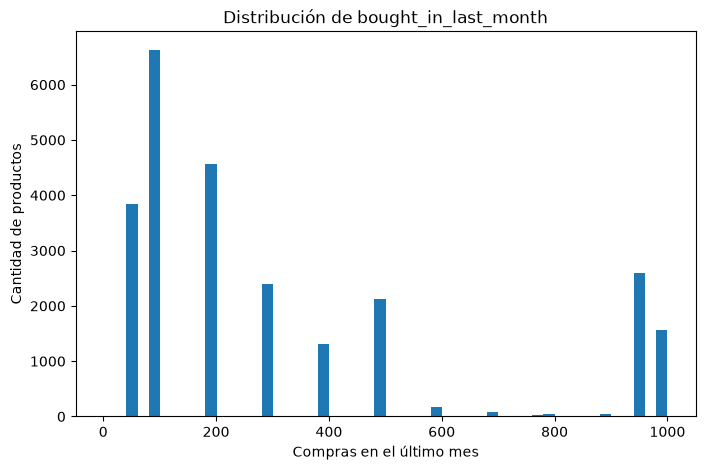

In [565]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['bought_in_last_month'])
plt.title('Boxplot de bought_in_last_month')
plt.ylabel('Compras en el último mes')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df['bought_in_last_month'], bins=50)
plt.title('Distribución de bought_in_last_month')
plt.xlabel('Compras en el último mes')
plt.ylabel('Cantidad de productos')
plt.show()

Luego de eliminar los outlier vemos claramente la manera en que se distribuyen los datos y ahora si podemos trabajar con ellos de una manera mas clara

In [566]:
df_corr = df[['Current/discounted_price', 'Rating', 'Number_of_reviews', 'bought_in_last_month', 'listed_price_numeric']].copy()

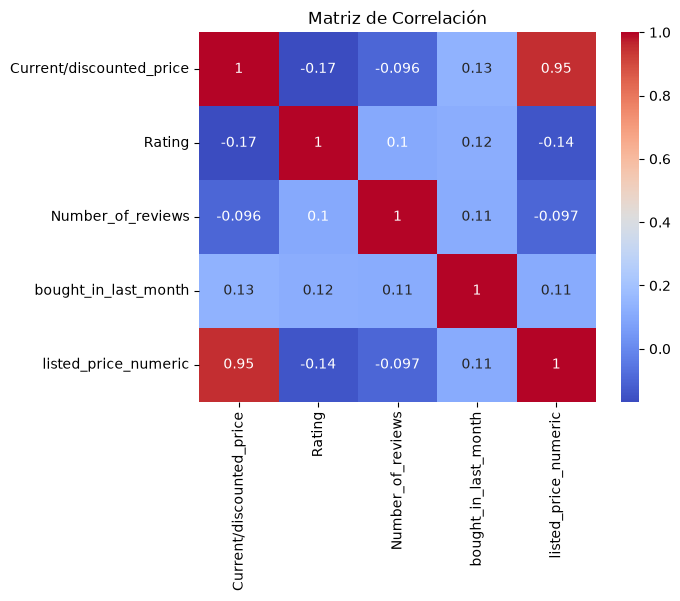

In [567]:
# Cálculo de la matriz de correlación
correlation_matrix = df_corr.corr()

# Visualización del heatmap con Seaborn
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

Current/dicounted_price y listed_price_numeric tienen una alta coorrelación, esto porque Current/dicounted_price tiene los precios originales de los productos que no tienen descuento, por lo cual vamos a eliminar la columna listed_price_numeric, asi eliminamos la coorrelación

In [568]:
df = df.drop(columns=['listed_price_numeric'])

In [569]:
df_corr = df[['Current/discounted_price', 'Rating', 'Number_of_reviews', 'bought_in_last_month', 'title_word_count']].copy()

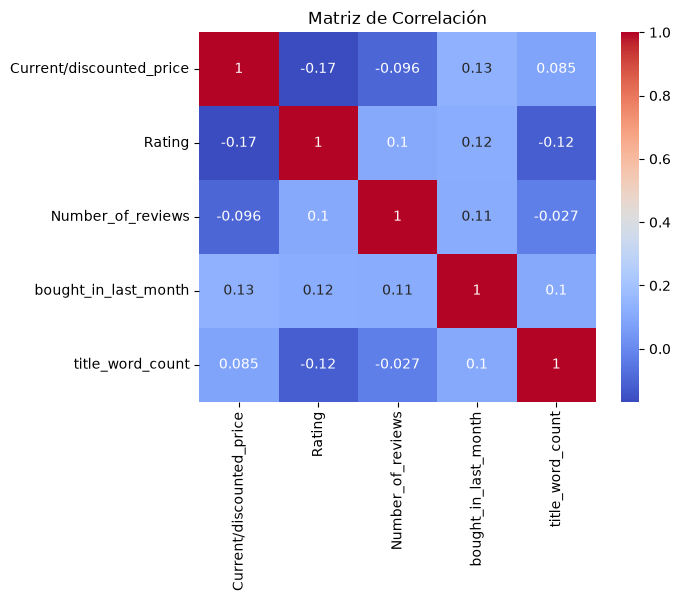

In [570]:
# Cálculo de la matriz de correlación
correlation_matrix = df_corr.corr()

# Visualización del heatmap con Seaborn
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

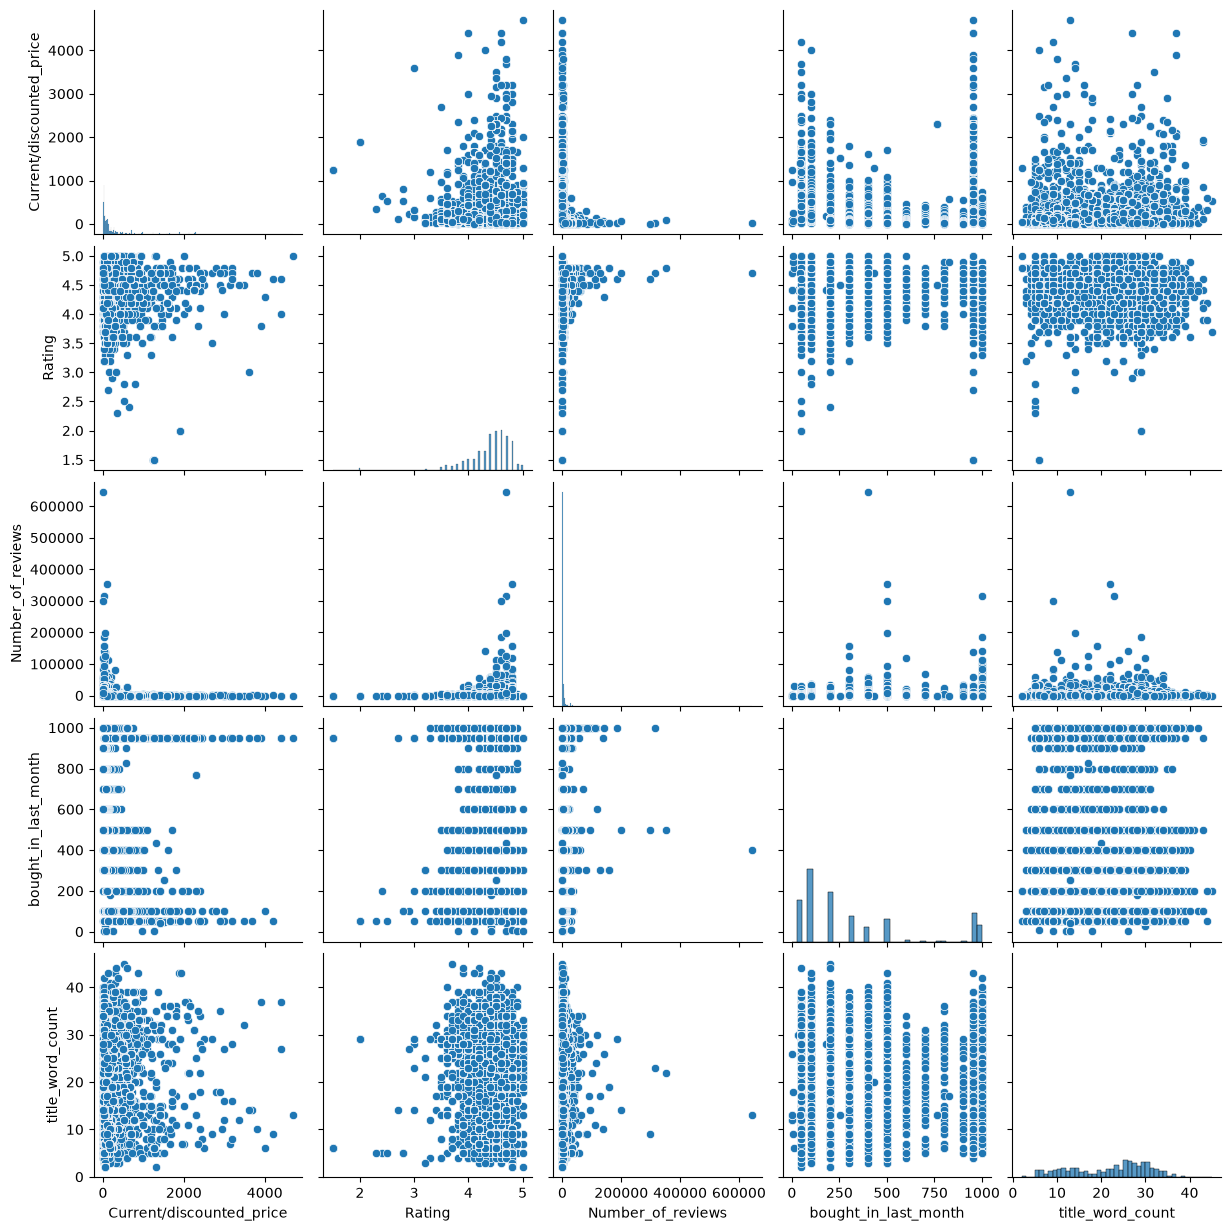

In [571]:
sns.pairplot(df_corr)

Apliquemos una transformación logaritmica

In [572]:
import numpy as np

df['log_price']        = np.log1p(df['Current/discounted_price'])
df['log_reviews']      = np.log1p(df['Number_of_reviews'])
df['log_bought']       = np.log1p(df['bought_in_last_month'])
df['log_delivery_cost']= np.log1p(df['delivery_cost'])
df['log_title_words']  = np.log1p(df['title_word_count'])

In [573]:
df_corr = df[['log_price','log_reviews', 'log_bought', 'log_delivery_cost', 'log_title_words']].copy()

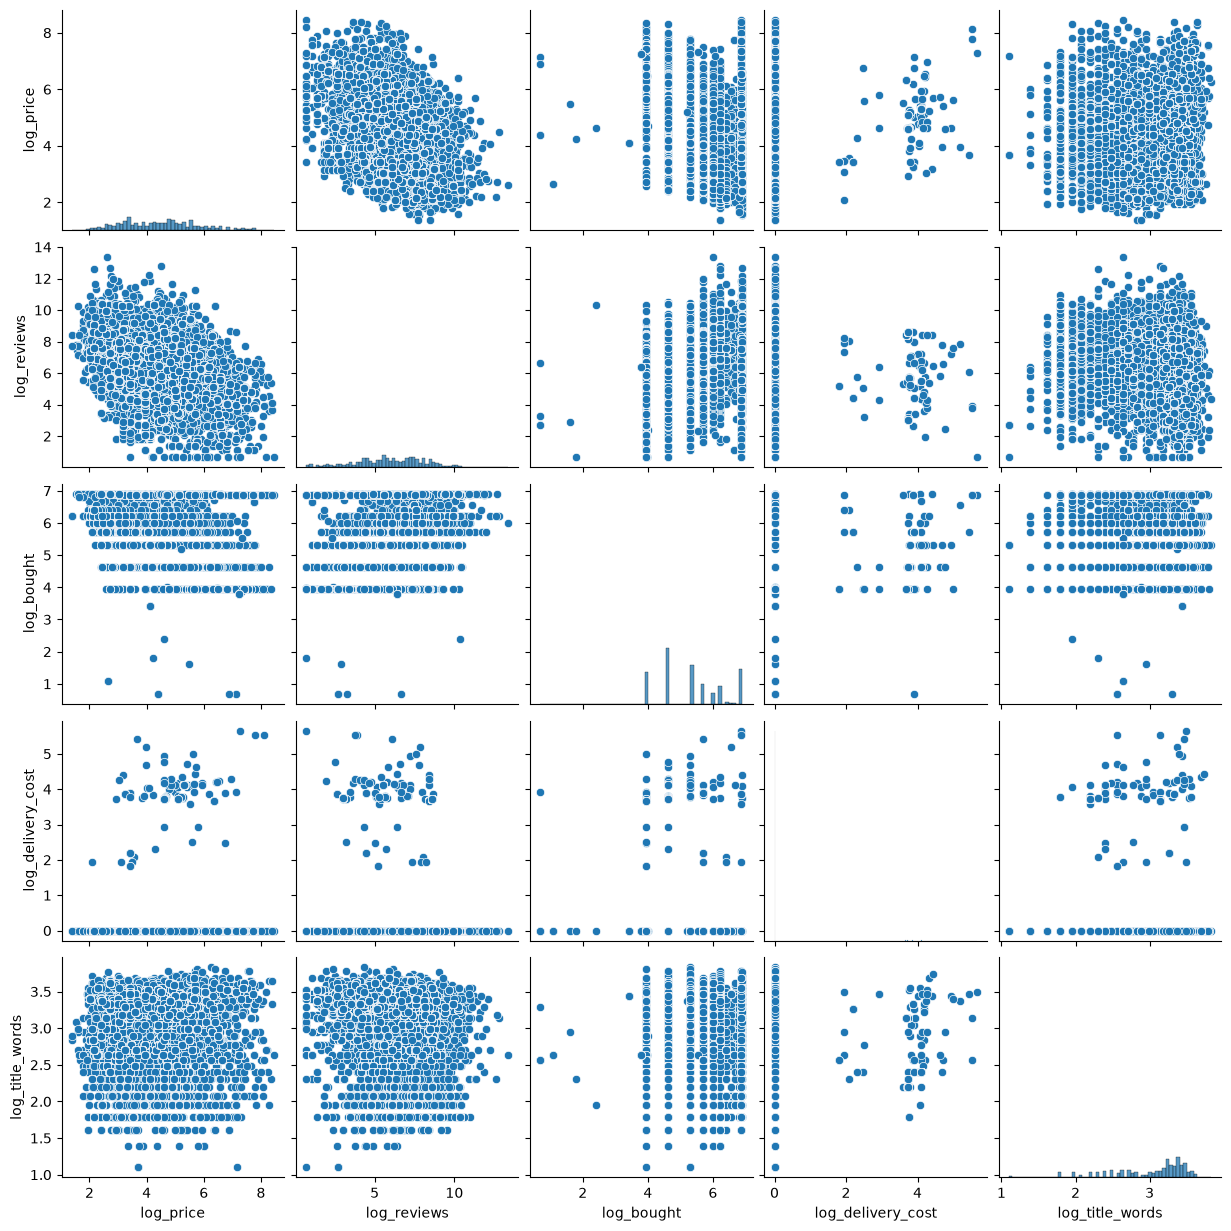

In [574]:
sns.pairplot(df_corr)

La transformación logarítmica mejoró sustancialmente la legibilidad de las distribuciones y la comparabilidad entre variables con escalas muy dispares. Las variables que antes aparecían como "pegadas al cero" ahora muestran su estructura real. Sin embargo, la transformación no reveló relaciones lineales nuevas entre las variables, lo que confirma que están genuinamente desacopladas en este dataset.

La transformación logarítmica evidencia que el log corrige el sesgo, comprime outliers y revela la estructura discreta de algunas variables, pero no genera relaciones lineales artificiales. Esto valida el uso del log como paso de preprocesamiento, al tiempo que confirma que las variables numéricas del dataset presentan una asociación débil entre sí

In [575]:
df_filtered.info()

<class 'pandas.DataFrame'>
Index: 26405 entries, 0 to 42674
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rating                    26405 non-null  float64
 1   Number_of_reviews         26057 non-null  float64
 2   bought_in_last_month      26405 non-null  float64
 3   Current/discounted_price  26405 non-null  float64
 4   has_discount              26405 non-null  int64  
 5   listed_price_numeric      26405 non-null  float64
 6   has_coupon                26405 non-null  int64  
 7   is_sponsored_flag         26405 non-null  int64  
 8   is_best_seller_flag       26405 non-null  int64  
 9   buy_box_available         26405 non-null  int64  
 10  has_sustainability_badge  26405 non-null  int64  
 11  title_word_count          26405 non-null  int64  
 12  is_free_delivery          26405 non-null  int64  
 13  delivery_cost             26405 non-null  float64
 14  is_outlier            

In [576]:
df_filtered.isna().sum()

Rating                        0
Number_of_reviews           348
bought_in_last_month          0
Current/discounted_price      0
has_discount                  0
listed_price_numeric          0
has_coupon                    0
is_sponsored_flag             0
is_best_seller_flag           0
buy_box_available             0
has_sustainability_badge      0
title_word_count              0
is_free_delivery              0
delivery_cost                 0
is_outlier                    0
dtype: int64